In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("/content/TrendPulse_Part2_Cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (46000, 21)


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,...,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country,total_engagement,engagement_rate,normalized_views,days_to_trend
0,UcYiQY22yfG,2017-11-14,Sunny Park - Cats (Lyric Video)!,QuietChallenge75,10,2017-11-14 05:57:11,Robots|Election,217915,14918.0,1363,...,https://i.ytimg.com/vi/UcYiQY22yfG/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,India,15580.0,7.149577,0.000601,0
1,EutcTEIciae,2017-11-14,Perfect Pasta Unboxing?!,UltimateUnboxing65,1,2017-11-08 13:18:04,Paris|Bangalore|Winter,115014,2739.0,287,...,https://i.ytimg.com/vi/EutcTEIciae/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,India,2948.0,2.563166,0.000316,6
2,rvuZ5CsBpg8,2017-11-14,Wild Budget Challenge!!,Brand NewSecret51,24,2017-11-14 18:16:59,Space,51028,1786.0,322,...,https://i.ytimg.com/vi/rvuZ5CsBpg8/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,India,2151.0,4.215333,0.000138,0
3,2yJGS3uxgMP,2017-11-14,Quiet Chess Mystery,UltimateUnboxing18,23,2017-11-11 20:04:47,Budget|Festival|Minecraft|Guitar,143370,5224.0,305,...,https://i.ytimg.com/vi/2yJGS3uxgMP/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,India,5795.0,4.041989,0.000394,3
4,W5pdmLZu7GK,2017-11-14,Quiet Festival Prank,HonestInterview42,24,2017-11-14 05:23:55,[none],390220,15079.0,947,...,https://i.ytimg.com/vi/W5pdmLZu7GK/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,India,17021.0,4.361898,0.001079,0


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Columns:
['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'country', 'total_engagement', 'engagement_rate', 'normalized_views', 'days_to_trend']

Missing values:
video_id                     0
trending_date                0
title                        0
channel_title                0
category_id                  0
publish_time                 0
tags                         0
views                        0
likes                       12
dislikes                     0
comment_count               36
thumbnail_link               0
comments_disabled            0
ratings_disabled             0
video_error_or_removed       0
description               1615
country                      0
total_engagement            48
engagement_rate             48
normalized_views             0
days_to_trend            

In [4]:
# Select numerical columns
metrics = [
    "views",
    "likes",
    "dislikes",
    "comment_count",
    "engagement_rate"
]

# Calculate statistical measures
statistics = pd.DataFrame({
    "Mean": df[metrics].mean(),
    "Median": df[metrics].median(),
    "Mode": df[metrics].mode().iloc[0],
    "Skewness": df[metrics].skew()
})

display(statistics.round(2))

,Mean,Median,Mode,Skewness
views,1179665.24,318389.00,16000.0,27.96
likes,45850.67,10211.00,0.0,44.52
dislikes,2329.12,595.00,0.0,23.89
comment_count,3452.71,1074.00,0.0,22.88
engagement_rate,3.88,3.67,0.0,1.02


In [5]:
# IQR outlier detection
for column in ["views", "likes", "engagement_rate"]:

    values = df[column].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_limit) |
        (values > upper_limit)
    ]

    print("\nColumn:", column)
    print("Lower limit:", round(lower_limit, 2))
    print("Upper limit:", round(upper_limit, 2))
    print("Number of outliers:", len(outliers))


Column: views
Lower limit: -912439.88
Upper limit: 1865943.12
Number of outliers: 5079

Column: likes
Lower limit: -34345.88
Upper limit: 66987.12
Number of outliers: 5263

Column: engagement_rate
Lower limit: 0.1
Upper limit: 7.46
Number of outliers: 1153


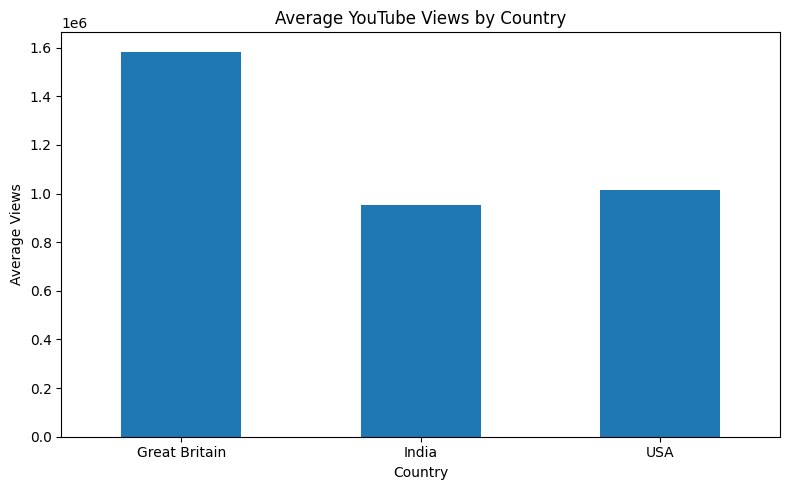

In [6]:
country_views = df.groupby("country")["views"].mean()

plt.figure(figsize=(8, 5))

country_views.plot(kind="bar")

plt.title("Average YouTube Views by Country")
plt.xlabel("Country")
plt.ylabel("Average Views")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

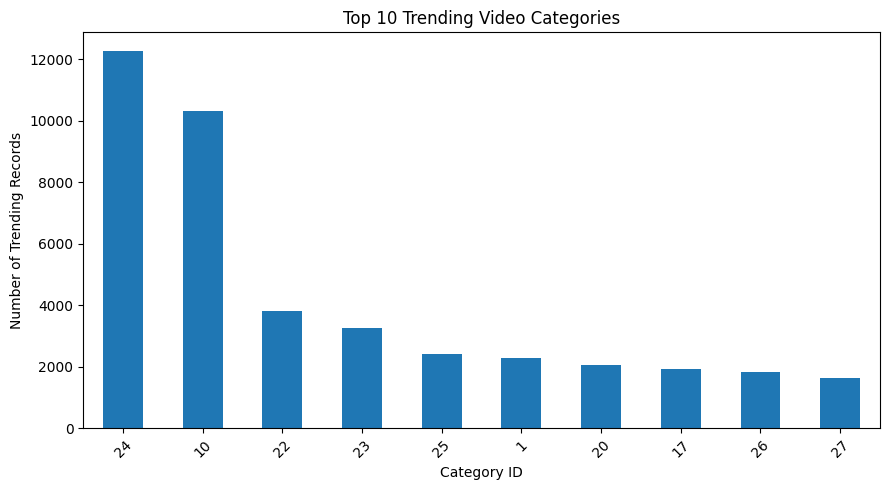

In [7]:
category_counts = df["category_id"].value_counts().head(10)

plt.figure(figsize=(9, 5))

category_counts.plot(kind="bar")

plt.title("Top 10 Trending Video Categories")
plt.xlabel("Category ID")
plt.ylabel("Number of Trending Records")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

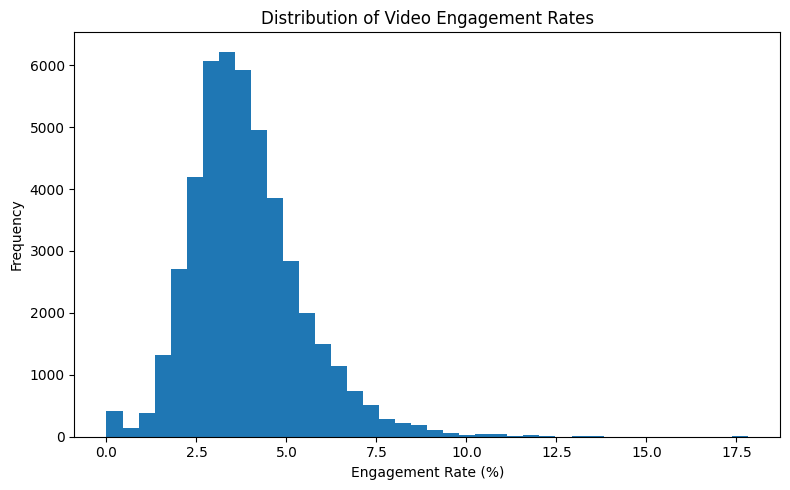

In [8]:
plt.figure(figsize=(8, 5))

df["engagement_rate"].dropna().plot(
    kind="hist",
    bins=40
)

plt.title("Distribution of Video Engagement Rates")
plt.xlabel("Engagement Rate (%)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

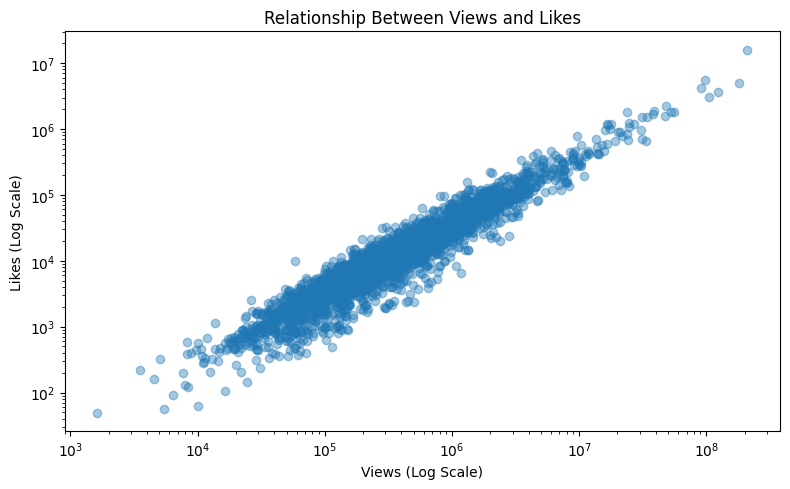

In [9]:
sample_data = df[
    (df["views"] > 0) &
    (df["likes"] > 0)
].sample(
    n=min(3000, len(df[(df["views"] > 0) & (df["likes"] > 0)])),
    random_state=42
)

plt.figure(figsize=(8, 5))

plt.scatter(
    sample_data["views"],
    sample_data["likes"],
    alpha=0.4
)

plt.xscale("log")
plt.yscale("log")

plt.title("Relationship Between Views and Likes")
plt.xlabel("Views (Log Scale)")
plt.ylabel("Likes (Log Scale)")

plt.tight_layout()
plt.show()

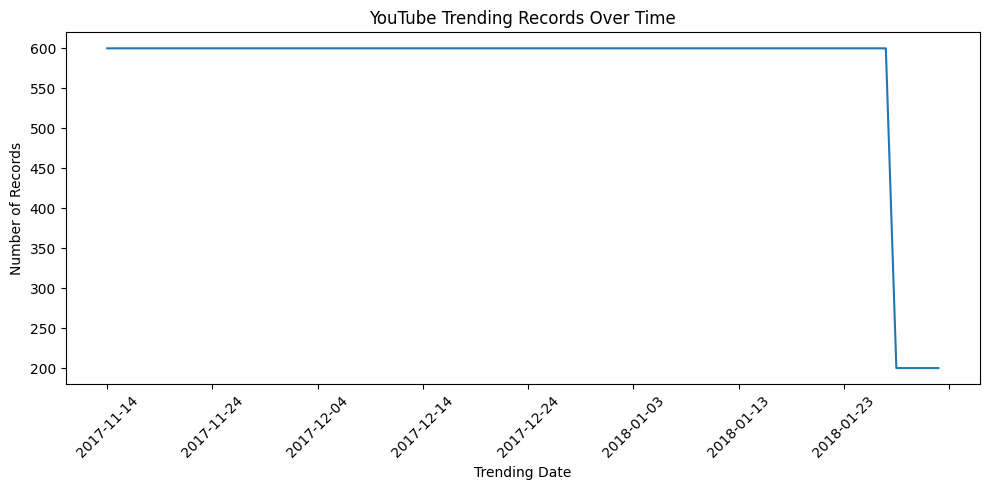

In [10]:
daily_trends = df.groupby("trending_date").size().sort_index()

plt.figure(figsize=(10, 5))

daily_trends.plot(kind="line")

plt.title("YouTube Trending Records Over Time")
plt.xlabel("Trending Date")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,views,likes,dislikes,comment_count,engagement_rate
views,1.000,0.921,0.889,0.916,0.038
likes,0.921,1.000,0.868,0.813,0.095
dislikes,0.889,0.868,1.000,0.889,0.101
comment_count,0.916,0.813,0.889,1.000,0.037
engagement_rate,0.038,0.095,0.101,0.037,1.000


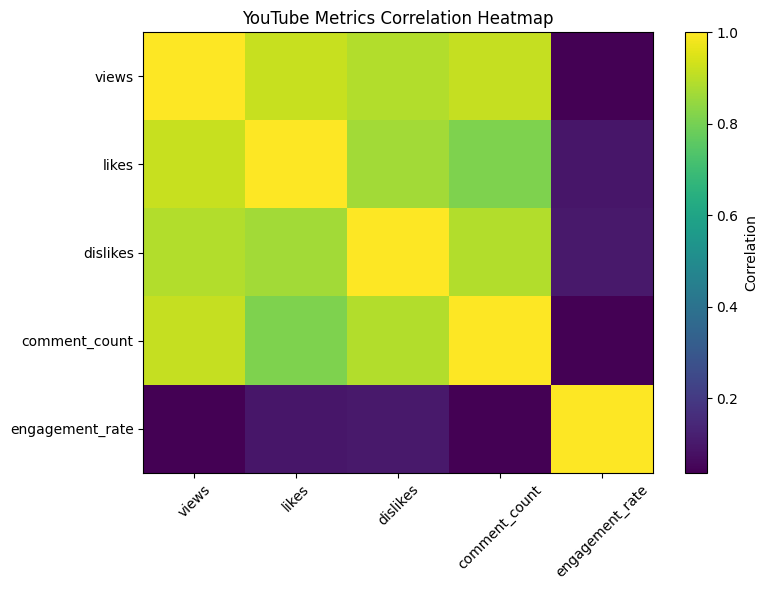

In [11]:
# Select numerical columns
correlation_data = df[
    ["views", "likes", "dislikes", "comment_count", "engagement_rate"]
]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

display(correlation_matrix.round(3))

# Create heatmap
plt.figure(figsize=(8, 6))

plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("YouTube Metrics Correlation Heatmap")
plt.tight_layout()
plt.show()

In [12]:
correlations = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
).stack()

print("Top 5 strongest correlations:")
print(
    correlations.abs().sort_values(ascending=False).head(5)
)

Top 5 strongest correlations:
views     likes            0.920917
          comment_count    0.915574
          dislikes         0.888529
dislikes  comment_count    0.888509
likes     dislikes         0.867620
dtype: float64


In [14]:
plot_data = df[
    (df["views"] > 0) &
    (df["likes"] > 0)
].sample(
    n=min(3000, len(df[(df["views"] > 0) & (df["likes"] > 0)])),
    random_state=42
)

fig = px.scatter(
    plot_data,
    x="views",
    y="likes",
    color="country",
    hover_data=["video_id", "title"],
    log_x=True,
    log_y=True,
    title="Interactive Views vs Likes by Country"
)

fig.show()

In [16]:
category_engagement = (
    df.groupby("category_id")["engagement_rate"]
    .mean()
    .reset_index()
)

fig = px.bar(
    category_engagement,
    x="category_id",
    y="engagement_rate",
    title="Average Engagement Rate by Video Category",
    labels={
        "category_id": "Category ID",
        "engagement_rate": "Average Engagement Rate (%)"
    }
)

fig.show()

In [17]:
# Create a unique identifier for each country-video pair
df["country_video_id"] = (
    df["country"].astype(str) + "::" +
    df["video_id"].astype(str)
)

# Calculate funnel stages
total_videos = df["country_video_id"].nunique()

videos_with_views = df.loc[
    df["views"] > 0, "country_video_id"
].nunique()

videos_with_likes = df.loc[
    (df["views"] > 0) & (df["likes"] > 0),
    "country_video_id"
].nunique()

videos_with_comments = df.loc[
    (df["views"] > 0) &
    (df["likes"] > 0) &
    (df["comment_count"] > 0),
    "country_video_id"
].nunique()

# Create funnel table
funnel = pd.DataFrame({
    "Stage": [
        "Total Videos",
        "Videos with Views",
        "Videos with Likes",
        "Videos with Comments"
    ],
    "Count": [
        total_videos,
        videos_with_views,
        videos_with_likes,
        videos_with_comments
    ]
})

display(funnel)

# Visualise funnel
fig = px.funnel(
    funnel,
    x="Count",
    y="Stage",
    title="YouTube Video Engagement Funnel"
)

fig.show()

,Stage,Count
0,Total Videos,15059
1,Videos with Views,15059
2,Videos with Likes,14890
3,Videos with Comments,14582


In [18]:
# Handle dates saved in either original YY.DD.MM or ISO format
date_values = df["trending_date"].astype(str)

if date_values.str.match(r"^\d{2}\.\d{2}\.\d{2}$").all():
    df["trending_date"] = pd.to_datetime(
        df["trending_date"],
        format="%y.%d.%m",
        errors="coerce"
    )
else:
    df["trending_date"] = pd.to_datetime(
        df["trending_date"],
        errors="coerce"
    )

print("Invalid dates:", df["trending_date"].isna().sum())

Invalid dates: 0


In [19]:
# Keep unique country-video-date records
activity = df[
    ["country", "video_id", "trending_date"]
].dropna().drop_duplicates()

# Find the first trending date of each video
first_dates = (
    activity.groupby(["country", "video_id"])["trending_date"]
    .min()
    .rename("first_trending_date")
    .reset_index()
)

# Attach first trending date to every record
activity = activity.merge(
    first_dates,
    on=["country", "video_id"],
    how="left"
)

# Calculate days since first trending
activity["days_since_first_trend"] = (
    activity["trending_date"] -
    activity["first_trending_date"]
).dt.days

# Calculate retention for selected days
retention_days = [2, 3, 5, 7]
retention = []

total_videos = len(first_dates)

for day in retention_days:

    retained = activity[
        activity["days_since_first_trend"] == day
    ][["country", "video_id"]].drop_duplicates()

    retained_count = len(retained)

    retention.append({
        "Day": day,
        "Retained Videos": retained_count,
        "Retention Rate (%)": (
            retained_count / total_videos * 100
            if total_videos > 0 else 0
        )
    })

retention_df = pd.DataFrame(retention)

display(retention_df.round(2))

,Day,Retained Videos,Retention Rate (%)
0,2,6274,41.66
1,3,4256,28.26
2,5,2043,13.57
3,7,1074,7.13


In [20]:
# Create a unique identifier for each country-video pair
activity["country_video_id"] = (
    activity["country"].astype(str) + "::" +
    activity["video_id"].astype(str)
)

# Assign each video to its first trending month
activity["cohort_month"] = (
    activity["first_trending_date"]
    .dt.to_period("M")
    .astype(str)
)

# Select the days we want to analyse
cohort_data = activity[
    activity["days_since_first_trend"].isin([0, 2, 3, 5, 7])
].copy()

# Count unique country-video pairs for each cohort and day
cohort_counts = cohort_data.pivot_table(
    index="cohort_month",
    columns="days_since_first_trend",
    values="country_video_id",
    aggfunc="nunique",
    fill_value=0
)

# Calculate the total size of each cohort
cohort_sizes = (
    activity.groupby("cohort_month")["country_video_id"]
    .nunique()
)

# Calculate retention percentages
cohort_retention = (
    cohort_counts.div(cohort_sizes, axis=0) * 100
)

display(cohort_retention.round(2))

days_since_first_trend,0,2,3,5,7
cohort_month,,,,,
2017-11,100.0,43.35,30.01,14.64,7.86
2017-12,100.0,42.51,29.43,14.83,7.94
2018-01,100.0,40.11,26.14,11.62,5.84
2018-02,100.0,0.00,0.00,0.00,0.00


In [21]:
print("TRENDPULSE – CONTENT STRATEGY RESEARCH")

print("\n1. Country with highest average views:")
print(country_views.idxmax())

print("\n2. Most frequent category:")
print(category_counts.idxmax())

print("\n3. Category with highest average engagement:")
print(
    category_engagement.loc[
        category_engagement["engagement_rate"].idxmax()
    ]
)

print("\n4. Overall average engagement rate:")
print(round(df["engagement_rate"].mean(), 2), "%")

print("\n5. Retention analysis:")
display(retention_df)

print("\n6. Strongest correlations:")
print(
    correlations.abs()
    .sort_values(ascending=False)
    .head(5)
)

TRENDPULSE – CONTENT STRATEGY RESEARCH

1. Country with highest average views:
Great Britain

2. Most frequent category:
24

3. Category with highest average engagement:
category_id        23.000000
engagement_rate     5.004631
Name: 8, dtype: float64

4. Overall average engagement rate:
3.88 %

5. Retention analysis:


,Day,Retained Videos,Retention Rate (%)
0,2,6274,41.662793
1,3,4256,28.262169
2,5,2043,13.566638
3,7,1074,7.131948



6. Strongest correlations:
views     likes            0.920917
          comment_count    0.915574
          dislikes         0.888529
dislikes  comment_count    0.888509
likes     dislikes         0.867620
dtype: float64


In [23]:
df.to_csv("TrendPulse_Part3_Analysis.csv", index=False)

statistics.to_csv("Descriptive_Statistics.csv")

funnel.to_csv("Engagement_Funnel.csv", index=False)

retention_df.to_csv("Retention_Analysis.csv", index=False)

cohort_retention.to_csv("Cohort_Analysis.csv")

print("All Part 3 output files saved successfully!")

All Part 3 output files saved successfully!


In [24]:
print("COUNTRY WITH HIGHEST AVERAGE VIEWS:")
print(country_views.idxmax())

print("\nTOP VIDEO CATEGORY:")
print(category_counts.index[0])

print("\nCATEGORY WITH HIGHEST ENGAGEMENT:")
print(
    category_engagement.loc[
        category_engagement["engagement_rate"].idxmax(),
        "category_id"
    ]
)

print("\nAVERAGE ENGAGEMENT RATE:")
print(round(df["engagement_rate"].mean(), 2), "%")

print("\nRETENTION RESULTS:")
display(retention_df)

print("\nCORRELATION RESULTS:")
display(correlations.abs().sort_values(ascending=False).head(5))

COUNTRY WITH HIGHEST AVERAGE VIEWS:
Great Britain

TOP VIDEO CATEGORY:
24

CATEGORY WITH HIGHEST ENGAGEMENT:
23

AVERAGE ENGAGEMENT RATE:
3.88 %

RETENTION RESULTS:


,Day,Retained Videos,Retention Rate (%)
0,2,6274,41.662793
1,3,4256,28.262169
2,5,2043,13.566638
3,7,1074,7.131948



CORRELATION RESULTS:


views     likes            0.920917
          comment_count    0.915574
          dislikes         0.888529
dislikes  comment_count    0.888509
likes     dislikes         0.867620
dtype: float64